# Deep Learning HW 2 Part 1
Author: Daniel Bond

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import random
from pathlib import Path

seed = 67
random.seed(seed)
np.random.seed(seed)

DATA_DIR = Path(".")
TRAIN_IMG_DIR = DATA_DIR / "train"
TEST_IMG_DIR = DATA_DIR / "test"
LABELS = ["Cat", "Dog", "Moris", "Motya", "Biatrix"]

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print(f"train: {train_df.shape}, test: {test_df.shape}")
train_df.head()

train: (12260, 6), test: (18673, 1)


,image_id,Cat,Dog,Moris,Motya,Biatrix
0,7e17a6e589f9c891857b32bbb3652d19b7d5a215,0,0,0,0,0
1,7ad97bd6c7ef98373f43f2bbd1e41b2bbff4687e,1,0,0,0,0
2,d29be872d012d8766c5942847d1d721788fd9511,0,1,0,0,0
3,bec7727bfc721629997d782ec020ee555990128f,0,1,0,0,0
4,58bb7362153d945f48721004bc8fb2ee73a855b0,0,1,0,0,0


## EDA and Metric Analysis

In [22]:
def lcount(df, name):
    count = df[name].sum()
    return f"{count}  |  {count/len(df)*100:.2f}%"
print("Labels:", 
    f"Cat {lcount(train_df, "Cat")}", 
    f"Dog {lcount(train_df, "Dog")}", 
    f"Moris {lcount(train_df, "Moris")}",
    f"Motya {lcount(train_df, "Motya")}",  
    f"Biatrix {lcount(train_df, "Biatrix")}", 
sep="\n\t")

labelless = (train_df[LABELS].sum(axis=1) == 0).sum()
print(f"Labelless: {labelless}  |  {labelless/len(train_df)*100:.2f}%")

Labels:
	Cat 5077  |  41.41%
	Dog 5025  |  40.99%
	Moris 56  |  0.46%
	Motya 42  |  0.34%
	Biatrix 41  |  0.33%
Labelless: 2162  |  17.63%


In [24]:
Y = train_df[LABELS]

multilabel = Y.T @ Y
display(multilabel)

for pet, parent in [("Moris", "Cat"), ("Motya", "Cat"), ("Biatrix", "Dog")]:
    pet_rows = Y[Y[pet] == 1]
    print(f"{pet}: {len(pet_rows)} images, with {parent}: {pet_rows[parent].sum()}  |  {pet_rows[parent].mean()*100:.0f}%")

print("\nUnique label combinations:")
display(Y.value_counts().rename("count").reset_index())

,Cat,Dog,Moris,Motya,Biatrix
Cat,5077,4,56,42,4
Dog,4,5025,4,0,41
Moris,56,4,56,10,4
Motya,42,0,10,42,0
Biatrix,4,41,4,0,41


Moris: 56 images, with Cat: 56  |  100%
Motya: 42 images, with Cat: 42  |  100%
Biatrix: 41 images, with Dog: 41  |  100%

Unique label combinations:


,Cat,Dog,Moris,Motya,Biatrix,count
0,1,0,0,0,0,4989
1,0,1,0,0,0,4984
2,0,0,0,0,0,2162
3,1,0,1,0,0,42
4,0,1,0,0,1,37
5,1,0,0,1,0,32
6,1,0,1,1,0,10
7,1,1,1,0,1,4


The data contains images, accompanied by multiple binary columns: `Cat`, `Dog`, `Moris`, `Motya`, `Biatrix`. 

The labels are nested: Moris and Motya are cats, and do not appear without `Cat` label, and Biatrix is a dog and doesn't appear without `Dog`.

17.6% of rows do not have any label - all columns are zero.

Rare classes of specific pets (three of the named pets) take up less than half percent each, which is severe class imbalance and will likely reflect on the selected for this challenge macro F1 score later in this assignment. The public private split is 33/67%, and I expect the distribution be different between them, such way that private scores will be multiple points lower.

The train set (12260) is smaller than test (18673) - one more interesting point about this challenge. That could mean that test has data yet unknown for the models, impacting scores, but that has to be checked with adversarial validation.

In [25]:
18673/12260

1.5230831973898857

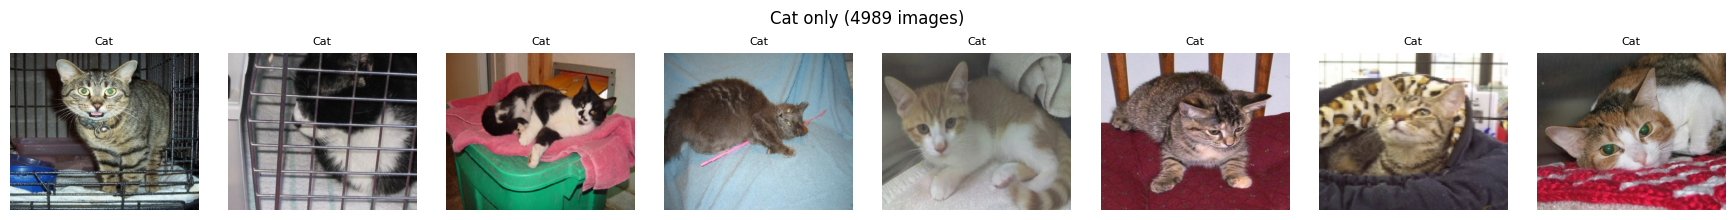

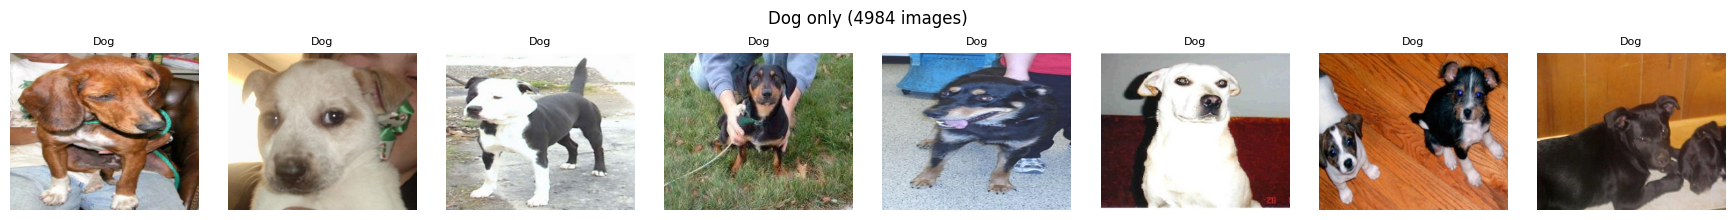

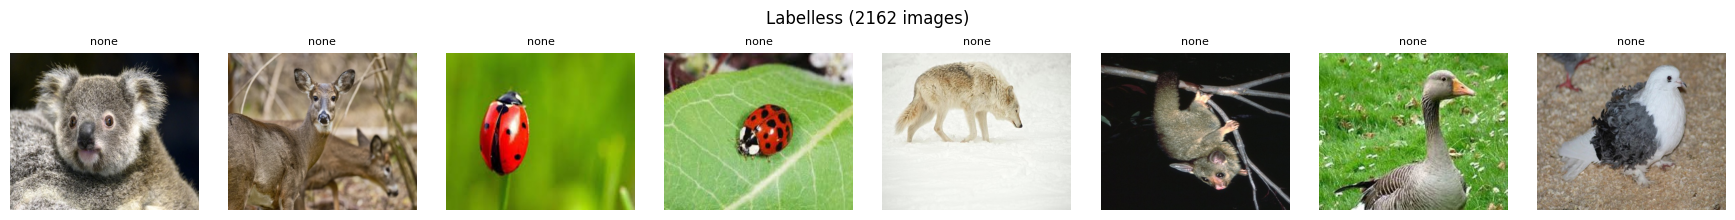

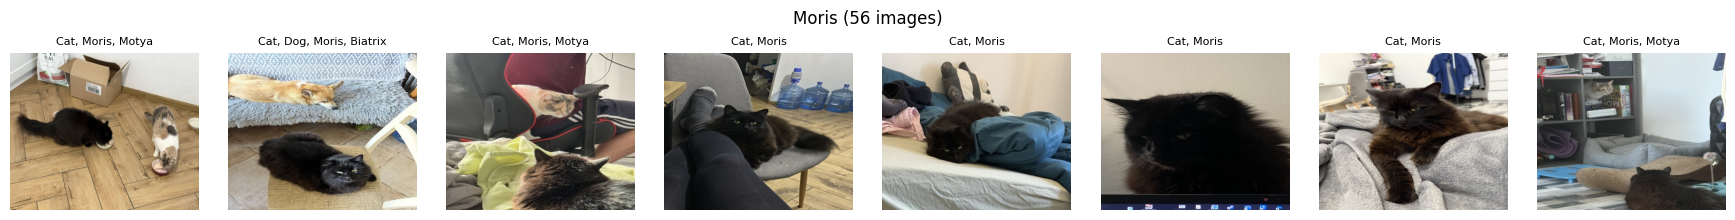

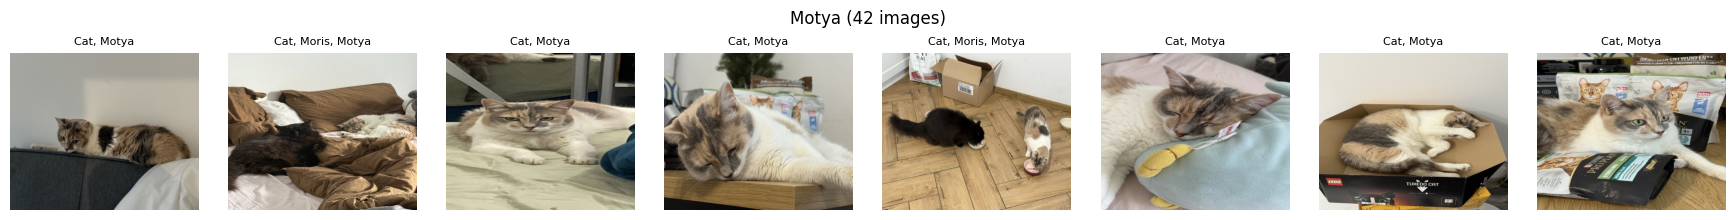

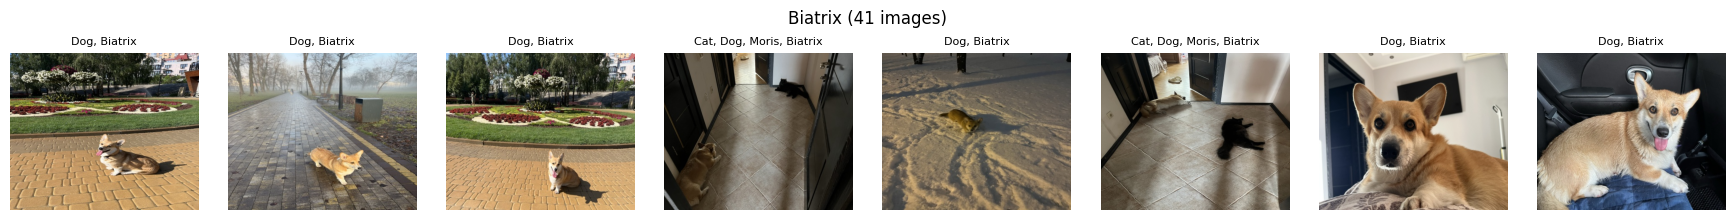

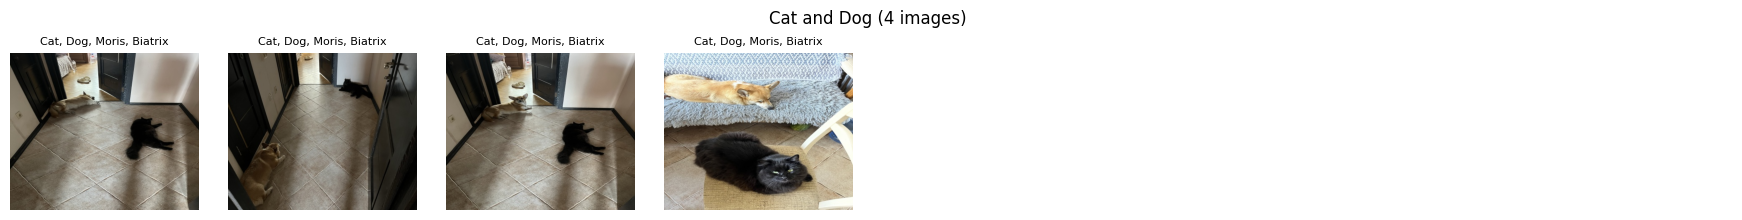

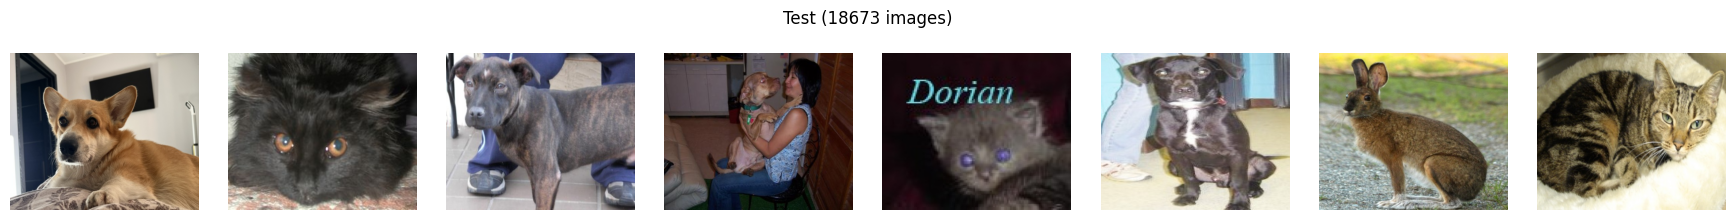

In [26]:
def show_grid(df, title, n=8, cols=8, img_dir=TRAIN_IMG_DIR):
    sample = df.sample(min(n, len(df)), random_state=seed)
    rows = int(np.ceil(len(sample) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 2.2))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, (_, row) in zip(np.atleast_1d(axes).ravel(), sample.iterrows()):
        ax.imshow(Image.open(img_dir / f"{row.image_id}.jpg"))
        if img_dir == TRAIN_IMG_DIR:
            ax.set_title(", ".join(l for l in LABELS if row[l]) or "none", fontsize=8)
    fig.suptitle(f"{title} ({len(df)} images)")
    plt.tight_layout()
    plt.show()


groups = {
    "Cat only": (Y["Cat"] == 1) & (Y.sum(axis=1) == 1),
    "Dog only": (Y["Dog"] == 1) & (Y.sum(axis=1) == 1),
    "Labelless": Y.sum(axis=1) == 0,
    "Moris": Y["Moris"] == 1,
    "Motya": Y["Motya"] == 1,
    "Biatrix": Y["Biatrix"] == 1,
    "Cat and Dog": (Y["Cat"] == 1) & (Y["Dog"] == 1),
}
for title, mask in groups.items():
    show_grid(train_df[mask], title)

show_grid(test_df, "Test", img_dir=TEST_IMG_DIR)

Every image is 450x375 RGB, so augmentations can be applied uniformly to all images.

Labelless images contain images of other animals, including some similar to labelled images, which can be confused by the model.

The pet photos have near-identical examples.

Pets:
1. Moris - black cat
2. Motya - light cat
3. Biatrix - corgy (probably)

### Metric

The chosen metric is macro F1 score, which comes with its advantages and problems.

Pros:
- Equal weight for all classes, so recognizing individual pets becomes an important part of the score
- Ignores true negatives, so large amount of labelless and not containing specific pets images do not influence the the respective scores.

Cons:
- Needs binary predictions, not probabilities, so threshold tuning is needed for each class.
- Very noisy on rare classes - one miss can drop the score noticeably. This makes small changes in scores and leaderboards pure noise.
- Label hierarchy is not considered: predicting `Moris` without `Cat` is not considered a contradiction by the metric, and only counts like false-neg for `Cat`.
- Hard to interpret model quality from the score only.

As classes are small, using stratified folds will be beneficial to keep distribution among folds and will solve an edge case in which a fold contains no sample of a class.

Challenge for this metric - 60% of the score is based on predicting individual pets (3/5 columns, with equal weight).

#### Complementary
1. Per-class F1, precision, recall, micro F1 - more detailed knowledge of which class influences the macro F1, great for interpretability of the main metric. Gap between micro/macro shows the negative impact of rare classes.
2. Per-class PR-AUC - needs no threshold, good for rare positives.
3. BCE/log-loss - the actual training metric, as macro F1 cannot be trained on directly.

#### Alternative
Macro PR-AUC: equal weight per class, as in main metric, doesn't need thresholds, informative even on low positive count, unlike ROC-AUC.